In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'core').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.figsize': (7, 4)})
FIG = ROOT / 'results' / 'figures'; DATA = ROOT / 'results' / 'data'

# 04 — The price of dictatorship: fixed-menu mechanisms vs all strategy-proof mechanisms

The paper's nested families are $\mathrm{LIP}\subsetneq\mathrm{IP}\subsetneq\mathrm{SD}\subsetneq\mathrm{SP}$
(linear increasing-price, increasing-price, swap-dictatorial, strategy-proof). It bounds
LIP from below (0.828) and SP from above (0.841), and says nothing about where SD sits. Here:

1. **the best swap-dictatorial mechanism on a type grid is itself an LP** (menu items are the
   variables; incentive and welfare constraints are linear in them) — `core.lp.solve_sd_lp`;
2. in the additive model its value is **exactly 5/6**, independently of the grid, certified by
   the three types $\{0,\tfrac12,1\}$ — and the dual uses *no* incentive constraint, which led
   to a four-line proof (`docs/theory/03_price_of_dictatorship.md`, Theorem A);
3. with complementarities the gap between fixed-menu and general strategy-proof mechanisms
   becomes large.

## 1. Additive model: SD $\le 5/6$

Theorem A (paraphrased): if $M(x,y)=\lambda A(x)+(1-\lambda)B(y)$ with $A$ depending only on
agent 1's report and $B$ only on agent 2's, then summing welfare over the four profiles
$(\tfrac12,0),(1,\tfrac12),(0,\tfrac12),(\tfrac12,1)$ (first best $\tfrac32$ each) gives
$\sum W\le 5$: the middle type's allocation cancels and the extreme types contribute at most
$\pm1$. So $\min W\le\tfrac54=\tfrac56\cdot\tfrac32$.

Numerically, the SD-LP returns $5/6$ for every grid we tried, and already for 3 types:

In [2]:
from fractions import Fraction
from core import lp, lip
from core.menu import FiniteMenuMechanism
import json
rows = []
for name, T in (("{0, 1/2, 1}", [0, .5, 1]), ("{0, 1/4, ..., 1}", np.linspace(0, 1, 5)), ("{j/20}", np.linspace(0, 1, 21)), ("{j/100}", np.linspace(0, 1, 101)), ("{j/200}", np.linspace(0, 1, 201))):
    r = lp.solve_sd_lp(0, types=T)
    rows.append({"type set": name, "SD-LP value": r.alpha, "as fraction": str(Fraction(r.alpha).limit_denominator(1000))})
pd.DataFrame(rows)

,type set,SD-LP value,as fraction
0,"{0, 1/2, 1}",0.833333,5/6
1,"{0, 1/4, ..., 1}",0.833333,5/6
2,{j/20},0.833333,5/6
3,{j/100},0.833333,5/6
4,{j/200},0.833333,5/6


In [3]:
r3 = lp.solve_sd_lp(0, types=[0, .5, 1])
print("menu (m1, m2) chosen by types 0, 1/2, 1:\n", np.c_[r3.types, r3.m1, r3.m2].round(3))
print("dual weights on competitiveness rows (j >= k):\n", r3.dual_welfare.round(4))
print("dual weights on IC rows:", r3.dual_ic.round(6).max(), "(all zero: incentive constraints are not needed for the bound)")
print("ratio per profile:\n", r3.ratio.round(4))

menu (m1, m2) chosen by types 0, 1/2, 1:
 [[0.  0.  1. ]
 [0.5 0.5 0.5]
 [1.  1.  0. ]]
dual weights on competitiveness rows (j >= k):
 [[0.     0.     0.    ]
 [0.3333 0.     0.    ]
 [0.     0.3333 0.    ]]
dual weights on IC rows: 0.0 (all zero: incentive constraints are not needed for the bound)
ratio per profile:
 [[1.     0.8333 1.    ]
 [0.8333 1.     0.8333]
 [1.     0.8333 1.    ]]


The LP-optimal mechanism on $\{0,\tfrac12,1\}$ is the obvious one — each type takes its own item,
the middle type splits — and it is exactly $5/6$-competitive there: the profiles $(1,\tfrac12)$
and $(\tfrac12,0)$ both give welfare $1.25$ against $1.5$.

## 2. Where does LIP sit?  Can any menu beat it on the continuum?

$\mathrm{LIP}(a^\star)$ achieves $0.82939$; the SD bound is $0.83333$; the SP bound (LP, large $N$) is
about $0.835$–$0.837$. So **LIP is within $0.004$ of the best possible menu mechanism**, and the
best non-dictatorial mechanism can gain at most $\approx0.007$ more.

Using a grid-optimal SD menu for *all* types does not transfer automatically (the menu exploits
the grid), but finer grids give better continuum menus, and from $N=200$ on **they beat LIP**:

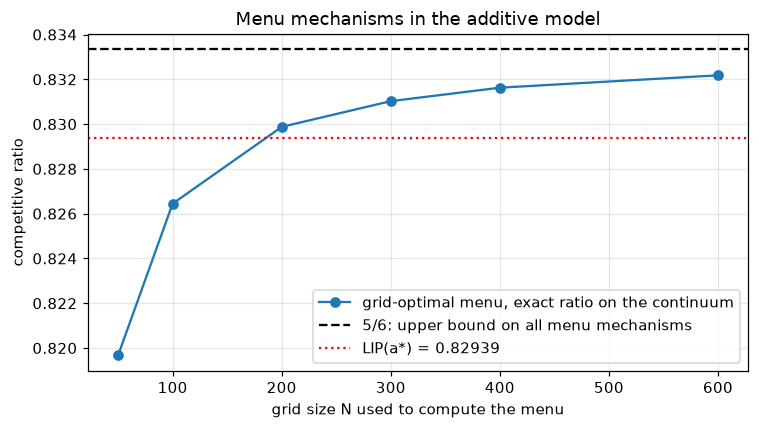

,N,n_items,sd_lp_grid,exact_continuum,x,y
0,50,31,0.83333,0.81967,0.22000,0.00000
1,100,58,0.83333,0.82645,0.21000,0.00000
2,200,113,0.83333,0.82988,0.20500,0.00000
3,300,160,0.83333,0.83102,0.20333,0.00000
4,400,183,0.83333,0.83163,0.20500,0.00000
5,600,265,0.83333,0.83218,1.00000,0.79833


In [4]:
sdc = pd.read_csv(DATA / "sd_continuum.csv"); sdc0 = sdc[sdc.eps == 0].sort_values("N")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sdc0.N, sdc0.exact_continuum, "o-", label="grid-optimal menu, exact ratio on the continuum")
ax.axhline(5/6, c="k", ls="--", label="5/6: upper bound on all menu mechanisms")
ax.axhline(json.loads((DATA / "lip_alpha_opt.json").read_text())["alpha_upper"], c="r", ls=":", label="LIP(a*) = 0.82939")
ax.set(xlabel="grid size N used to compute the menu", ylabel="competitive ratio", title="Menu mechanisms in the additive model"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "04_sd_continuum.png"); plt.show()
sdc0[["N", "n_items", "sd_lp_grid", "exact_continuum", "x", "y"]].round(5)

So there *are* menu mechanisms better than every LIP mechanism (the $N=200$ menu already gives
$0.8299>0.8294$), and the sequence approaches $5/6$ from below. A direct Nelder–Mead search over
small menus was a dead end (0.816). The question is settled analytically:

### Theorem C — the optimal menu in closed form attains exactly $5/6$

Write $d(x)=m_1(x)-m_2(x)$ for the dictator's net share. For $x>y$,
$W(x,y)=1+\tfrac12(x-y)[d(x)-d(y)]$ and $\mathrm{OPT}=1+(x-y)$, so the ratio is $\ge5/6$ everywhere
iff $d(x)-d(y)\ge h(x-y):=\tfrac53-\tfrac1{3(x-y)}$. Incentive compatibility just needs $d$
non-decreasing (shares then follow from the envelope formula). The steepest admissible $d$ is
built from $D(x)=\max_k[\tfrac{5k}3-\tfrac{k^2}{3x}]$ ($=0$ on $[0,\tfrac15]$, $\tfrac53-\tfrac1{3x}$ on
$[\tfrac15,\tfrac35]$, $\tfrac{10}3-\tfrac4{3x}$ on $[\tfrac35,1]$), which reaches $D(1)=2$ exactly, so
$d(x)=\tfrac12[D(x)-D(1-x)]$ fits in $[-1,1]$ and its shares lie in $[0,1]$. Full proof in
`docs/theory/03_price_of_dictatorship.md`.

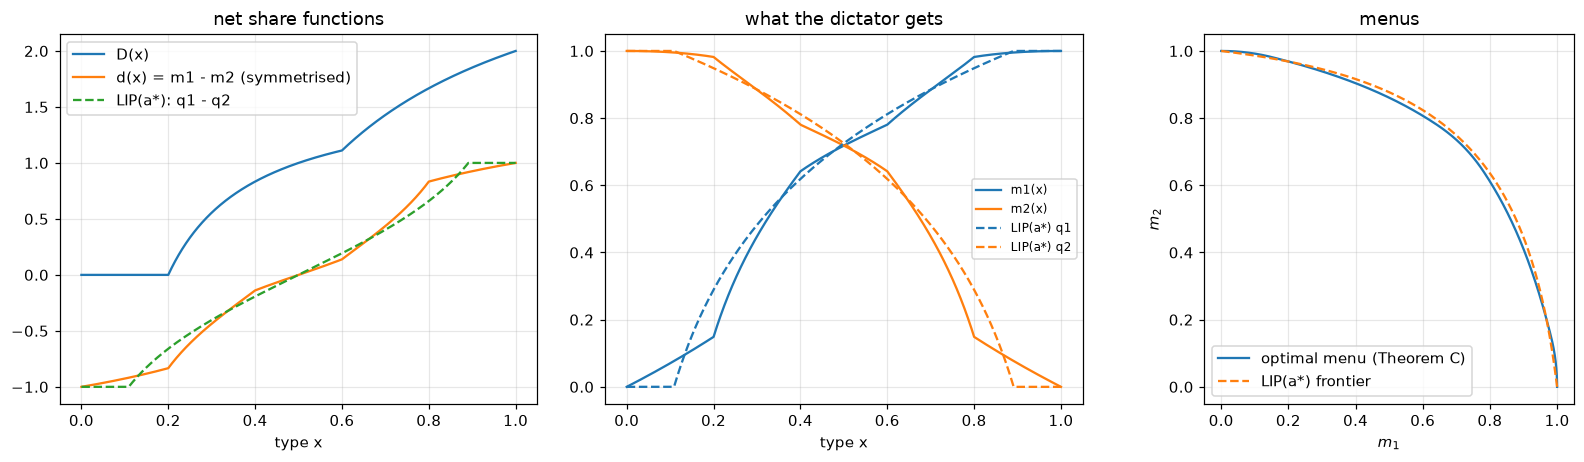

,menu items,exact ratio on the continuum,5/6
0,101,0.829582,0.833333
1,501,0.832583,0.833333
2,2001,0.833146,0.833333


In [5]:
from core.menu import optimal_sd_choice, optimal_sd_menu, steepest_chain_D
opt = json.loads((DATA / "lip_alpha_opt.json").read_text())
x = np.linspace(0, 1, 1001)
m1, m2 = optimal_sd_choice(x); q1, q2 = lip.bundle_additive(x, opt["a_star"])
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ax[0].plot(x, steepest_chain_D(x), label="D(x)"); ax[0].plot(x, m1 - m2, label="d(x) = m1 - m2 (symmetrised)"); ax[0].plot(x, q1 - q2, "--", label="LIP(a*): q1 - q2")
ax[0].set(xlabel="type x", title="net share functions"); ax[0].legend()
ax[1].plot(x, m1, label="m1(x)"); ax[1].plot(x, m2, label="m2(x)"); ax[1].plot(x, q1, "--", c="C0", label="LIP(a*) q1"); ax[1].plot(x, q2, "--", c="C1", label="LIP(a*) q2")
ax[1].set(xlabel="type x", title="what the dictator gets"); ax[1].legend(fontsize=8)
ax[2].plot(m1, m2, label="optimal menu (Theorem C)"); ax[2].plot(q1, q2, "--", label="LIP(a*) frontier"); ax[2].set(xlabel="$m_1$", ylabel="$m_2$", title="menus", aspect="equal"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG / "04_optimal_menu.png"); plt.show()
rows = [{"menu items": n, "exact ratio on the continuum": FiniteMenuMechanism(optimal_sd_menu(n), 0.0).exact_ratio()[0]} for n in (101, 501, 2001)]
pd.DataFrame(rows).assign(**{"5/6": 5/6}).round(6)

The discretised menus converge to $5/6$ (8001 items: 0.83328; the only loss is that off-grid
types pick a neighbouring item). The optimal dictator is *less* greedy than LIP at the balanced
type — $(0.70,0.70)$ instead of $(0.72,0.72)$ — and more decisive near the extremes.

For comparison, the $N=100$ menu alone:

In [6]:
r = lp.solve_sd_lp(100, eps=0.0)
items = np.unique(np.round(np.c_[r.m1, r.m2, r.m12], 9), axis=0)
f = FiniteMenuMechanism(items, 0.0)
val, pt = f.exact_ratio()
print(f"N=100 SD-LP menu: {len(items)} distinct items; value on the grid {r.alpha:.4f}; exact value on the continuum {val:.4f} at {pt}")
opt = json.loads((DATA / "lip_alpha_opt.json").read_text())
print(f"LIP(a*) on the continuum: {opt['alpha_lower']:.5f}")
res = sorted(DATA.glob("menu_opt_eps0_K*.json"))
for p in res:
    d = json.loads(p.read_text()); print(f"direct finite-menu optimiser ({p.name}): exact ratio {d['ratio']:.5f} with {len(d['items'])} items")

N=100 SD-LP menu: 58 distinct items; value on the grid 0.8333; exact value on the continuum 0.8264 at (1.0, 0.7899999974800002)
LIP(a*) on the continuum: 0.82936
direct finite-menu optimiser (menu_opt_eps0_K6.json): exact ratio 0.81604 with 12 items


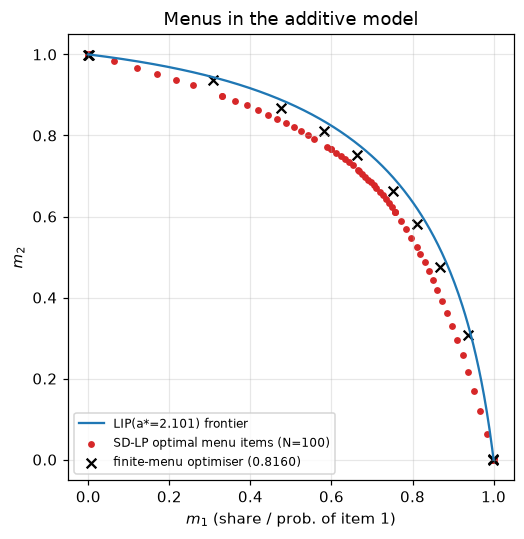

In [7]:
# the LIP(a*) frontier against the grid-optimal SD menu points
fig, ax = plt.subplots(figsize=(5.5, 5))
z = np.linspace(0, 1, 300)
ax.plot(z, lip.Q(1 - lip.cost(z, opt["a_star"]), opt["a_star"]), label=f"LIP(a*={opt['a_star']:.3f}) frontier")
ax.scatter(r.m1, r.m2, s=12, c="C3", label="SD-LP optimal menu items (N=100)")
for p in res[-1:]:
    d = json.loads(p.read_text()); it = np.array(d["items"]); ax.scatter(it[:, 0], it[:, 1], s=40, marker="x", c="k", label=f"finite-menu optimiser ({d['ratio']:.4f})")
ax.set(xlabel="$m_1$ (share / prob. of item 1)", ylabel="$m_2$", title="Menus in the additive model", aspect="equal"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_menus_eps0.png"); plt.show()

## 3. Complementarities: dictatorship becomes expensive

With $\varepsilon>0$ the SD-LP values are again rational and grid-independent; and the optimal
menus are tiny. At $\varepsilon=\tfrac12$ the menu is $\{(\tfrac37,0),(0,\tfrac37),\text{balanced pooling lottery}\}$
and its *exact* ratio on the continuum is $6/7$: the dictator never takes more than $3/7$ of
anything — the mechanism is closer to equal split than to a dictatorship.

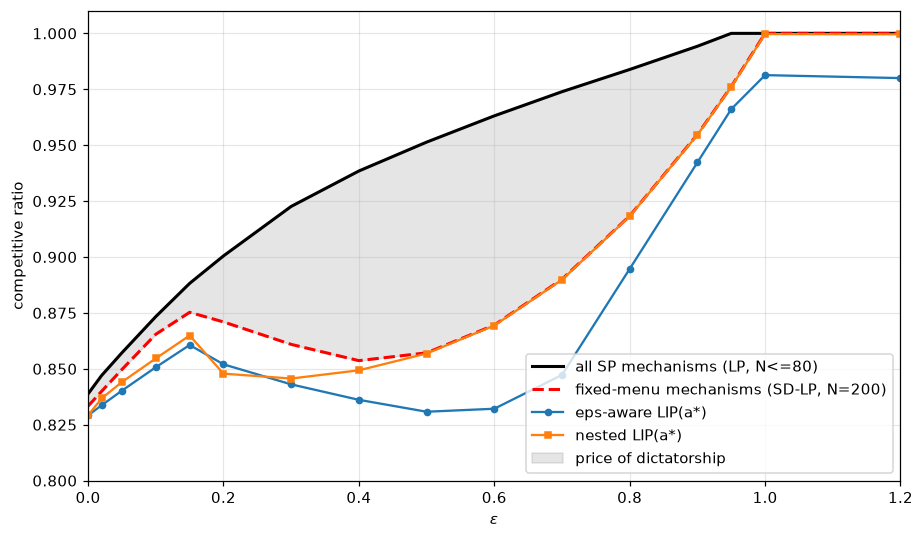

,eps,alpha_sd,fraction,rho_A=(5+2e)/6 (eps<=1/2),rho_B=(1+e)/(1+2e-e^2),SP-LP
0,0.00,0.83333,5/6,0.83333,1.00000,0.83881
1,0.02,0.83995,740/881,0.84000,0.98115,0.84702
2,0.05,0.84971,1600/1883,0.85000,0.95672,0.85719
3,0.10,0.86545,521/602,0.86667,0.92437,0.87336
4,0.15,0.87526,1677/1916,0.88333,0.90020,0.88821
5,0.20,0.87097,27/31,0.90000,0.88235,0.90049
6,0.30,0.86093,130/151,0.93333,0.86093,0.92262
7,0.40,0.85366,35/41,0.96667,0.85366,0.93846
8,0.50,0.85714,6/7,1.00000,0.85714,0.95137
9,0.60,0.86957,20/23,NaN,0.86957,0.96312


In [8]:
sd100 = pd.read_csv(DATA / "sd_lp_curve.csv")
sd = sd100[sd100.N == sd100.N.max()].sort_values("eps")
lpc = pd.read_csv(DATA / "lp_eps_curve.csv"); lpN = lpc.sort_values("N").groupby("eps", as_index=False).last().sort_values("eps")   # largest N available per eps
det = pd.read_csv(DATA / "eps_lip_best.csv").drop_duplicates("eps", keep="last").sort_values("eps"); nes = pd.read_csv(DATA / "eps_lip_best_nested.csv").drop_duplicates("eps", keep="last").sort_values("eps")
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(lpN.eps, lpN.alpha, "k-", lw=2, label=f"all SP mechanisms (LP, N<={lpc.N.max()})")
ax.plot(sd.eps, sd.alpha_sd, "r--", lw=2, label=f"fixed-menu mechanisms (SD-LP, N={sd100.N.max()})")
ax.plot(det.eps, det.lower, "o-", ms=4, label="eps-aware LIP(a*)"); ax.plot(nes.eps, nes.lower, "s-", ms=4, label="nested LIP(a*)")
ax.fill_between(sd.eps, sd.alpha_sd, np.interp(sd.eps, lpN.eps, lpN.alpha), color="gray", alpha=0.2, label="price of dictatorship")
ax.set(xlabel=r"$\varepsilon$", ylabel="competitive ratio", xlim=(0, 1.2), ylim=(0.8, 1.01)); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "04_price_of_dictatorship.png"); plt.show()
tab = sd[["eps", "alpha_sd"]].copy(); tab["fraction"] = [str(Fraction(v).limit_denominator(2000)) for v in tab.alpha_sd]
tab["rho_A=(5+2e)/6 (eps<=1/2)"] = np.where(tab.eps <= 0.5, (5 + 2 * tab.eps) / 6, np.nan); tab["rho_B=(1+e)/(1+2e-e^2)"] = (1 + tab.eps) / (1 + 2 * tab.eps - tab.eps**2)
tab = tab.merge(lpN[["eps", "alpha"]].rename(columns={"alpha": "SP-LP"}), on="eps", how="left"); tab.round(5)

In [9]:
rows = []
for e in (0.25, 0.5, 0.75):
    r = lp.solve_sd_lp(100, eps=e)
    items = np.unique(np.round(np.c_[r.m1, r.m2, r.m12], 6), axis=0)
    f = FiniteMenuMechanism(items, e); val, pt = f.exact_ratio()
    rows.append({"eps": e, "SD-LP (grid)": r.alpha, "distinct menu items": len(items), "exact ratio of that menu on the continuum": val, "worst profile": pt,
                 "menu": [tuple(np.round(i, 3)) for i in items]})
pd.DataFrame(rows)

,eps,SD-LP (grid),distinct menu items,exact ratio of that menu on the continuum,worst profile,menu
0,0.25,0.869565,51,0.862665,"(0.2599977575123332, 0.0)","[(0.0, 0.652, -0.0), (0.046, 0.632, 0.013), (0..."
1,0.50,0.857143,3,0.857143,"(1.0, 0.0)","[(0.0, 0.429, -0.0), (0.273, 0.246, 0.046), (0..."
2,0.75,0.903226,3,0.903226,"(0.4900010038115314, 0.4900010038115314)","[(-0.0, 0.226, 0.0), (0.171, 0.058, 0.002), (0..."


For $\varepsilon=\tfrac12$ (and $\tfrac34$) the grid-optimal finite menu is optimal on the
continuum as well, so the SD value is *exact*: $6/7$ and $28/31$ — these are the closed forms
$\rho_B(\varepsilon)=(1+\varepsilon)/(1+2\varepsilon-\varepsilon^2)$ of Theorem B, attained by the
"modest dictator" menu $\{(s^\star,0),(0,s^\star)\}$, $s^\star=(1-\varepsilon^2)/(1+2\varepsilon-\varepsilon^2)$.
For small $\varepsilon$ the binding argument is the middle-type one, $\rho_A=(5+2\varepsilon)/6$.
Note in the figure above that **nested LIP($a^\star$) tracks the SD bound almost exactly for
$\varepsilon\ge0.5$**: within the menu class it is essentially optimal, and its whole shortfall
against the SP-LP is the price of dictatorship. Compare with the SP-LP
($\approx0.95$ and $\approx0.98$): the price of dictatorship is about $0.1$ at
$\varepsilon=\tfrac12$. The reason is structural — with complementarities the efficient rule
pools when agents agree and splits when they disagree, which a rule that mixes two one-sided
choices cannot do (Theorem A's argument). The LP-optimal mechanisms do exactly that (notebook
02-style heatmaps for $\varepsilon=0.5$ below): nearly take-all when both prefer the same item,
a nested split otherwise.

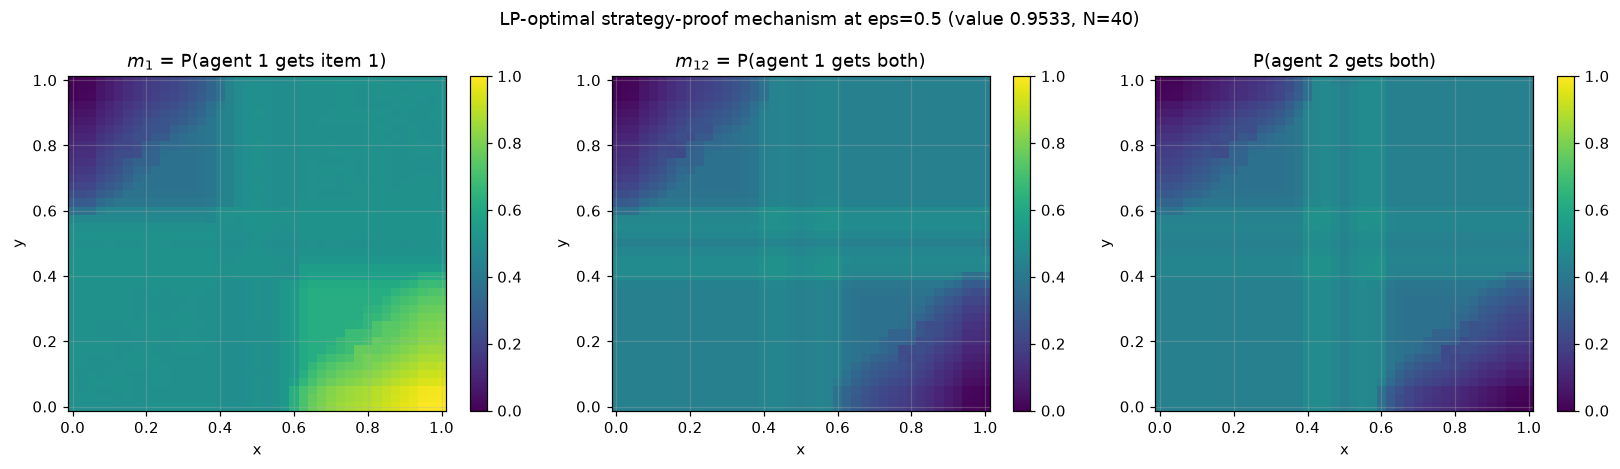

In [10]:
N = 40; e = 0.5
r = lp.solve_sp_lp(N, eps=e, symmetric=True); g = np.arange(N + 1) / N; X, Y = np.meshgrid(g, g, indexing="ij")
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for k, (M, name) in enumerate(((r.m1, "$m_1$ = P(agent 1 gets item 1)"), (r.m12, "$m_{12}$ = P(agent 1 gets both)"), (1 - r.m1 - r.m2 + r.m12, "P(agent 2 gets both)"))):
    im = ax[k].pcolormesh(X, Y, M, cmap="viridis", vmin=0, vmax=1, shading="nearest"); plt.colorbar(im, ax=ax[k]); ax[k].set(title=name, xlabel="x", ylabel="y")
plt.suptitle(f"LP-optimal strategy-proof mechanism at eps={e} (value {r.alpha:.4f}, N={N})"); plt.tight_layout(); plt.savefig(FIG / "04_lp_mechanism_eps05.png"); plt.show()

## 4. Beyond dictatorship: "split if strongly opposed, else modest dictator" (SMD)

Theorem A's obstruction is that a dictatorial rule cannot react to *agreement*. The simplest
rule that can: with $\tau=(1+\varepsilon)/2$, if $x\ge\tau$ and $y\le1-\tau$ (or the mirror image)
**split** — each gets her preferred item; otherwise a fair-coin dictator takes a share $s$ of her
preferred item. A strong type ($x\ge\tau$) prefers the split and a moderate one the fallback
*exactly* at the threshold, so the rule is strategy-proof for every $s$ (Proposition D,
`docs/theory/04_beyond_dictatorship.md`; brute-force check below). Its ratio has the closed form

$$\rho_{SMD}(\varepsilon)=\begin{cases}2(1+\varepsilon)^2/(3+3\varepsilon+2\varepsilon^2) & \varepsilon\le\tfrac12\\ (1+\varepsilon)^2/(1+3\varepsilon) & \varepsilon\ge\tfrac12\end{cases}$$

which beats every fixed-menu mechanism for $\varepsilon>0.366$ (0.900 vs $6/7$ at $\varepsilon=\tfrac12$).
The fallback menu can itself be optimised by an LP given the split region (`lp.solve_split_menu_lp`).

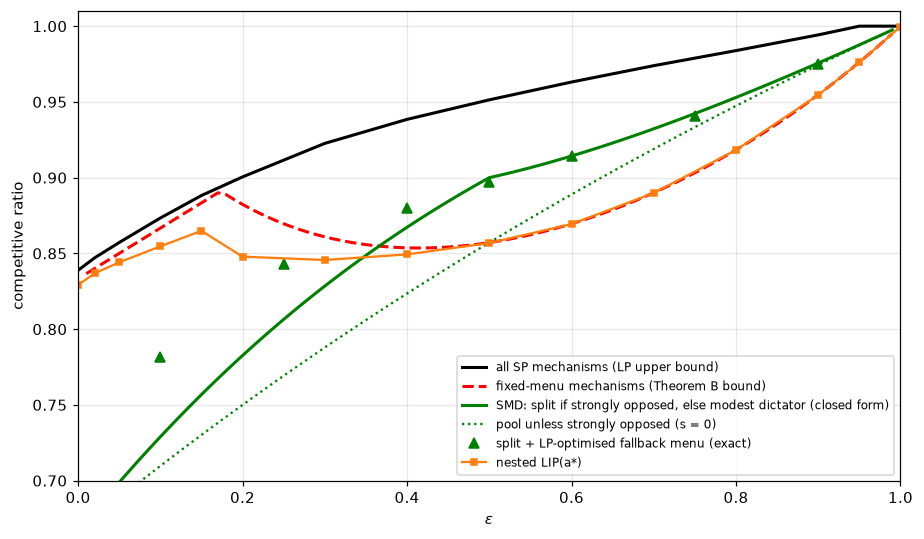

,eps,SMD closed form,SMD IC violation,split + LP-optimal menu (grid N=40),"same, exact on continuum",its IC violation (continuum grid),menu items
0,0.10,0.7289,0.0,0.7965,0.7818,0.0119,21
1,0.25,0.8065,0.0,0.8665,0.8427,0.0000,21
2,0.40,0.8673,0.0,0.8957,0.8800,0.0000,9
3,0.50,0.9000,0.0,0.9062,0.8973,0.0000,3
4,0.60,0.9143,0.0,0.9143,0.9143,0.0000,2
5,0.75,0.9423,0.0,0.9520,0.9408,0.0000,2
6,0.90,0.9757,0.0,0.9874,0.9750,0.0000,2


In [11]:
from core import split
e_grid = np.linspace(0.01, 0.99, 99)
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(lpN.eps, lpN.alpha, "k-", lw=2, label="all SP mechanisms (LP upper bound)")
ax.plot(e_grid, np.minimum((5 + 2 * e_grid) / 6, (1 + e_grid) / (1 + 2 * e_grid - e_grid**2)), "r--", lw=2, label="fixed-menu mechanisms (Theorem B bound)")
ax.plot(e_grid, split.ratio_closed_form(e_grid), "g-", lw=2, label="SMD: split if strongly opposed, else modest dictator (closed form)")
ax.plot(e_grid, split.ratio_closed_form(e_grid, s=0.0), "g:", label="pool unless strongly opposed (s = 0)")
rows = []
for e in (0.1, 0.25, 0.4, 0.5, 0.6, 0.75, 0.9):
    r = lp.solve_split_menu_lp(40, e); tau = (1 + e) / 2
    items = np.unique(np.round(np.c_[r.m1, r.m2, r.m12], 9), axis=0)
    f = FiniteMenuMechanism(items, e, split_tau=tau)
    rows.append({"eps": e, "SMD closed form": float(split.ratio_closed_form(e)), "SMD grid min": split.ratio(X[X >= Y], Y[X >= Y], e).min() if False else np.nan,
                 "SMD IC violation": split.ic_violation(e, n=81), "split + LP-optimal menu (grid N=40)": r.alpha,
                 "same, exact on continuum": f.exact_ratio()[0], "its IC violation (continuum grid)": f.ic_violation(201), "menu items": len(items)})
sm = pd.DataFrame(rows)
ax.plot(sm.eps, sm["same, exact on continuum"], "g^", ms=7, label="split + LP-optimised fallback menu (exact)")
ax.plot(nes.eps, nes.lower, "s-", c="C1", ms=4, label="nested LIP(a*)")
ax.set(xlabel=r"$\varepsilon$", ylabel="competitive ratio", xlim=(0, 1), ylim=(0.7, 1.01)); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_beyond_dictatorship.png"); plt.show()
sm.drop(columns=["SMD grid min"]).round(4)

The brute-force incentive checks are zero for SMD, and for the LP-optimised fallbacks at
$\varepsilon\ge0.25$ (at $\varepsilon=0.1$ the grid-optimised fallback violates incentive
compatibility between grid types by about $0.012$ — the split-IC constraints were imposed at
grid types only — so that point is not a valid mechanism). Note that the LP's *grid* value overstates what its menu achieves on the
continuum: for $\varepsilon\ge\tfrac12$ the closed-form SMD is at least as good on the continuum
(and at $\varepsilon=0.6$ it is optimal within the split-or-menu class: all three numbers coincide),
while for $\varepsilon\approx0.25$–$0.45$ the optimised fallback adds about $0.02$–$0.05$.

## Summary

* New theorem: the best swap-dictatorial mechanism (indeed any mixture of two one-sided rules)
  is **exactly** $5/6$-competitive for two items — upper bound by a four-profile argument,
  attained by an explicit closed-form menu. LIP($a^\star$) is within $0.004$ of it.
* The best fixed-menu mechanism for any $\varepsilon$ is computable by an LP; for
  $\varepsilon=\tfrac12$ it is a 3-item menu with exact ratio $6/7$.
* Under complementarities the right design is *not* dictatorial. The simple SMD rule
  ("split if strongly opposed, else modest dictator") is strategy-proof with closed-form ratio
  $(1+\varepsilon)^2/(1+3\varepsilon)$ for $\varepsilon\ge\tfrac12$ and beats every menu for
  $\varepsilon>0.366$; optimising its fallback by an LP helps for $\varepsilon\lesssim0.45$. Closing the
  remaining gap to the LP bound (0.900 vs 0.951 at $\varepsilon=\tfrac12$) is open.